In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("Dataset/stroke_risk_prediction_dataset.csv")

In [4]:
df

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,22.0,Male,Spain,171.7,113.4,38.5,139,78,81,...,Average,3.2,41.0,Government,Urban,Medium,40,Improve Diet Quality,No,Moderate
49996,49997,61.0,Male,South Africa,164.6,64.0,23.6,123,92,87,...,Poor,0.7,92.0,Student,Rural,Medium,59,Reduce Sodium Intake,Yes,Moderate
49997,49998,76.0,Female,Spain,148.9,56.4,25.4,153,93,95,...,Average,0.7,31.0,Retired,Urban,High,64,Improve Diet Quality,Yes,Moderate
49998,49999,31.0,Other,Italy,183.7,75.7,22.4,108,77,76,...,Poor,3.4,90.0,Retired,Rural,Low,26,Continue Regular Exercise,No,Low


In [5]:
print("Ukuran data")
print("Baris :", df.shape[0])
print("Kolom:", df.shape[1])

Ukuran data
Baris : 50000
Kolom: 40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    50000 non-null  int64  
 1   Age                           49781 non-null  float64
 2   Gender                        50000 non-null  object 
 3   Country                       50000 non-null  object 
 4   Height_cm                     48475 non-null  float64
 5   Weight_kg                     48477 non-null  float64
 6   BMI                           50000 non-null  float64
 7   Blood_Pressure_Systolic       50000 non-null  int64  
 8   Blood_Pressure_Diastolic      50000 non-null  int64  
 9   Heart_Rate                    50000 non-null  int64  
 10  Blood_Glucose                 49040 non-null  float64
 11  HbA1c                         48994 non-null  float64
 12  Total_Cholesterol             48996 non-null  float64
 13  H

In [7]:
df.head()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate


In [8]:
df.describe(include="all")

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
count,50000.000000,49781.000000,50000,50000,48475.000000,48477.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,48949,48946.000000,48949.000000,50000,50000,50000,50000.000000,50000,50000,50000
unique,NaN,NaN,3,25,NaN,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,5,2,3,NaN,13,2,3
top,NaN,NaN,Other,Italy,NaN,NaN,NaN,NaN,NaN,NaN,...,Excellent,NaN,NaN,Self-Employed,Urban,Medium,NaN,Monitor Blood Pressure,Yes,Moderate
freq,NaN,NaN,16791,2058,NaN,NaN,NaN,NaN,NaN,NaN,...,16454,NaN,NaN,10096,25041,16800,NaN,8650,36579,34375
mean,25000.500000,53.903096,NaN,NaN,170.125582,87.506141,30.901386,135.061420,84.840620,82.521020,...,NaN,5.001214,59.947742,NaN,NaN,NaN,54.782320,NaN,NaN,NaN
std,14433.901067,21.070953,NaN,NaN,14.484573,24.565490,10.254560,20.526562,14.685149,16.141082,...,NaN,2.892267,34.987073,NaN,NaN,NaN,13.996729,NaN,NaN,NaN
min,1.000000,18.000000,NaN,NaN,145.000000,45.000000,11.900000,100.000000,60.000000,55.000000,...,NaN,0.000000,0.000000,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
25%,12500.750000,36.000000,NaN,NaN,157.600000,66.200000,22.700000,117.000000,72.000000,68.000000,...,NaN,2.500000,30.000000,NaN,NaN,NaN,45.000000,NaN,NaN,NaN
50%,25000.500000,54.000000,NaN,NaN,170.100000,87.500000,30.100000,135.000000,85.000000,83.000000,...,NaN,5.000000,60.000000,NaN,NaN,NaN,54.000000,NaN,NaN,NaN
75%,37500.250000,72.000000,NaN,NaN,182.800000,108.800000,37.800000,153.000000,98.000000,97.000000,...,NaN,7.500000,90.000000,NaN,NaN,NaN,64.000000,NaN,NaN,NaN


In [9]:
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [10]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Age                         219
Height_cm                  1525
Weight_kg                  1523
Blood_Glucose               960
HbA1c                      1006
Total_Cholesterol          1004
HDL                        1021
LDL                        1050
Triglycerides              1032
Sleep_Hours                1026
Medication_Adherence       1051
Exercise_Hours_Per_Week    1054
Daily_Walking_Minutes      1051
dtype: int64

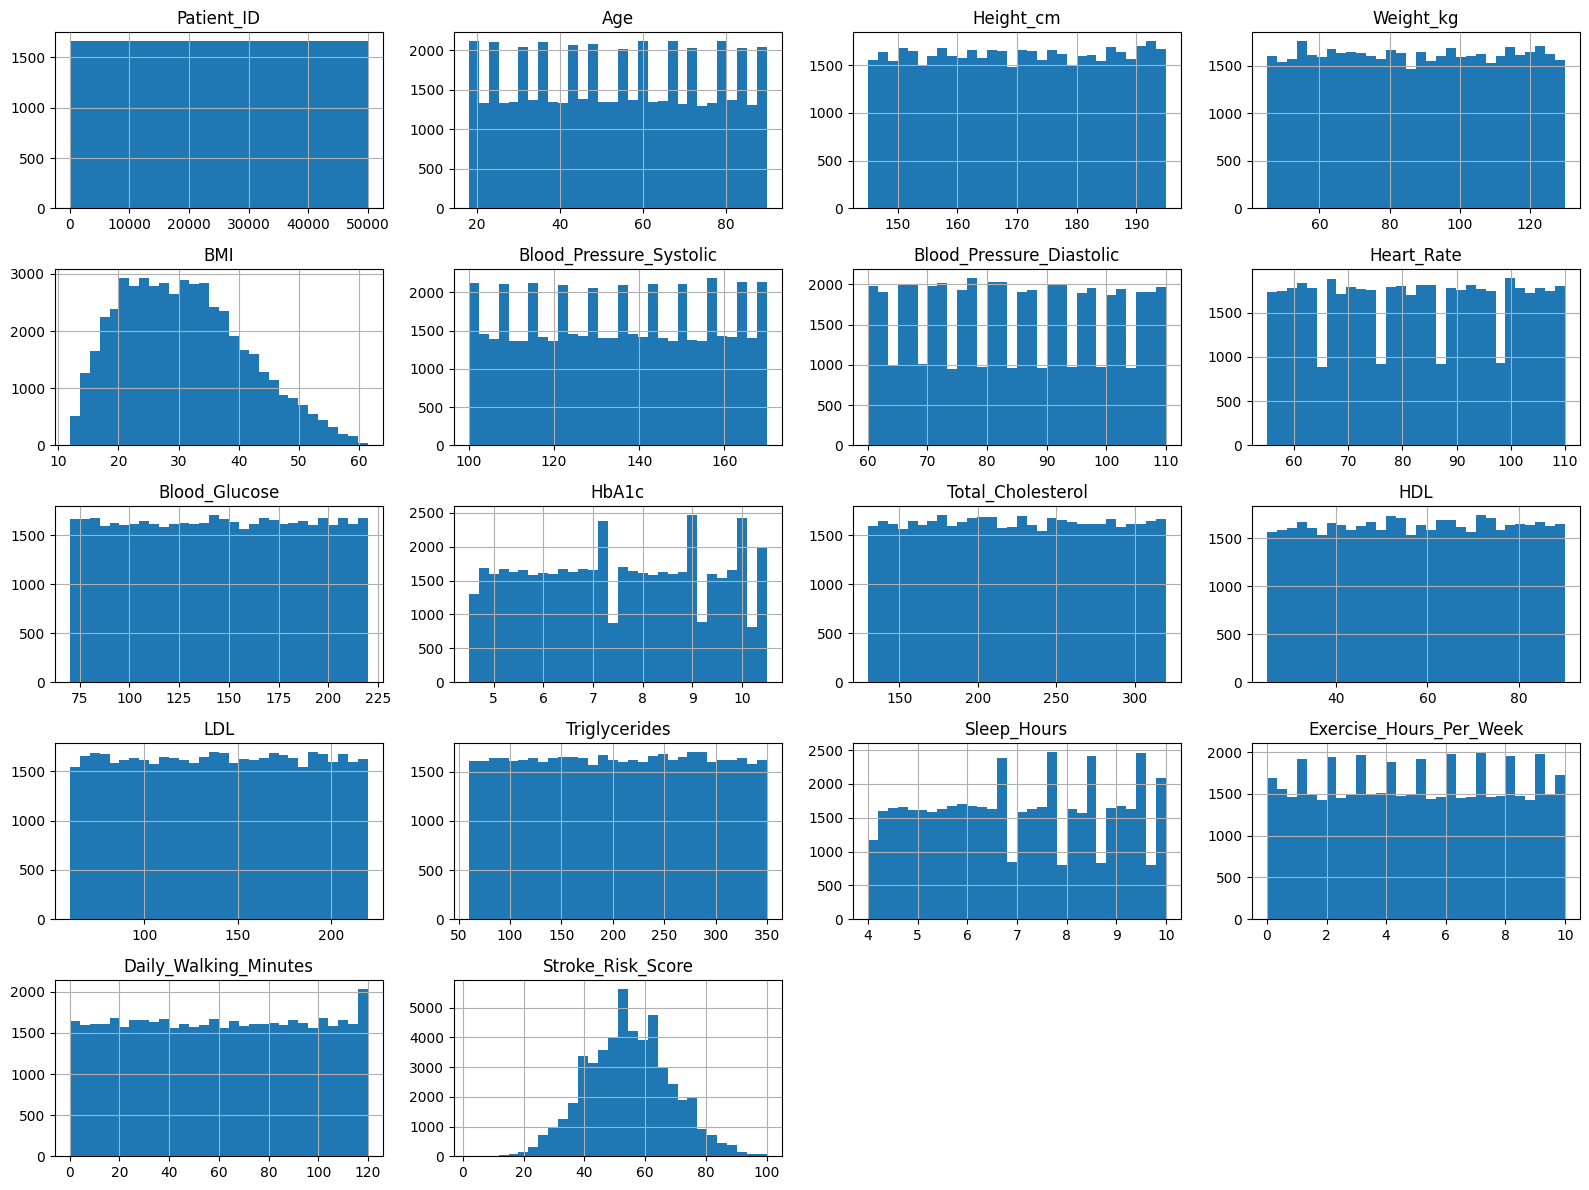

In [11]:
df.hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

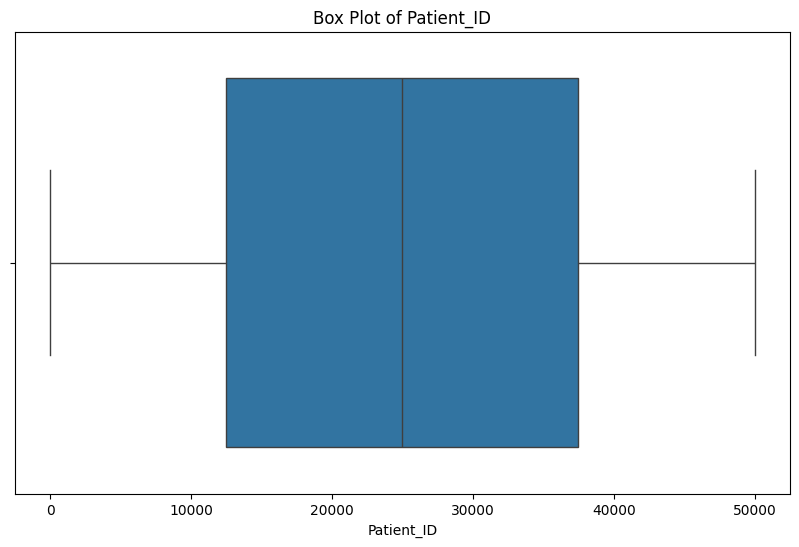

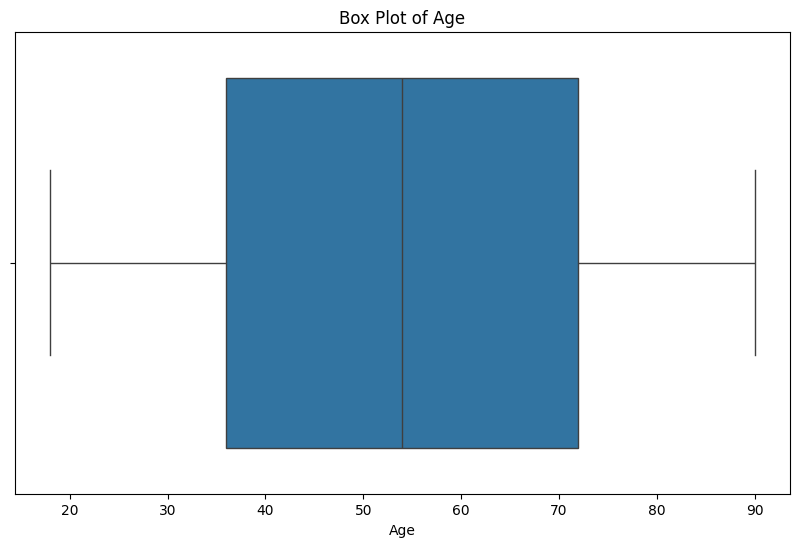

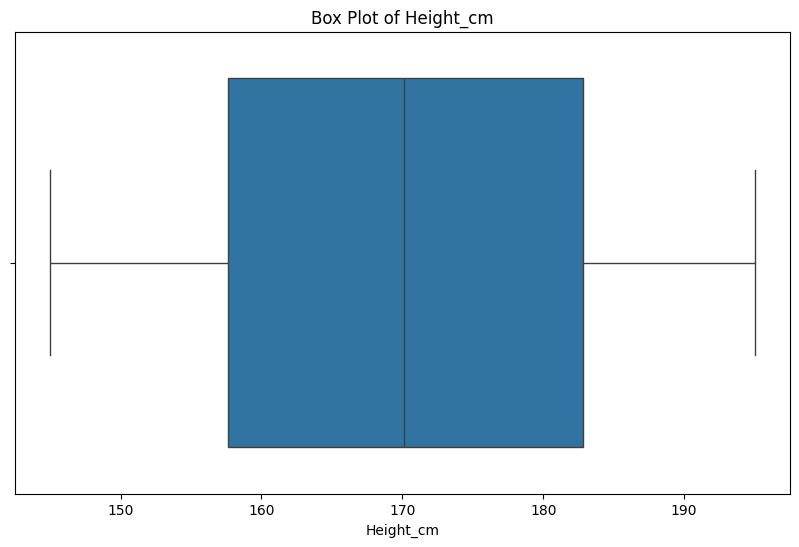

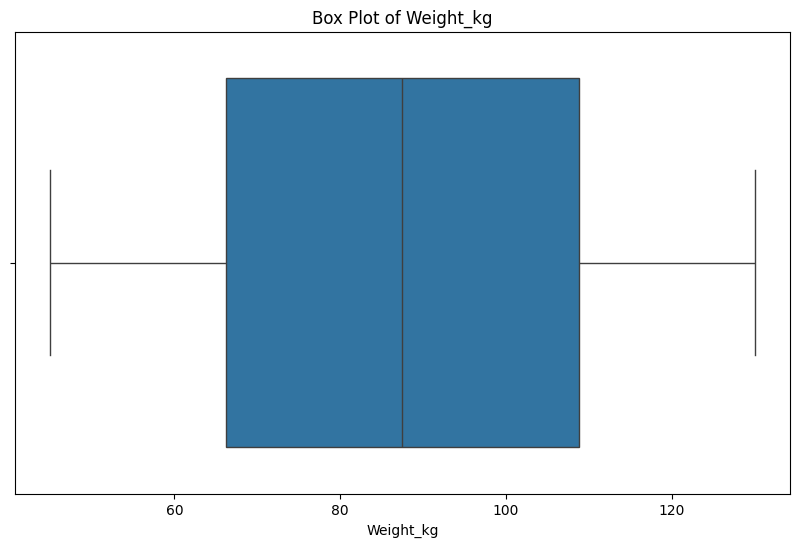

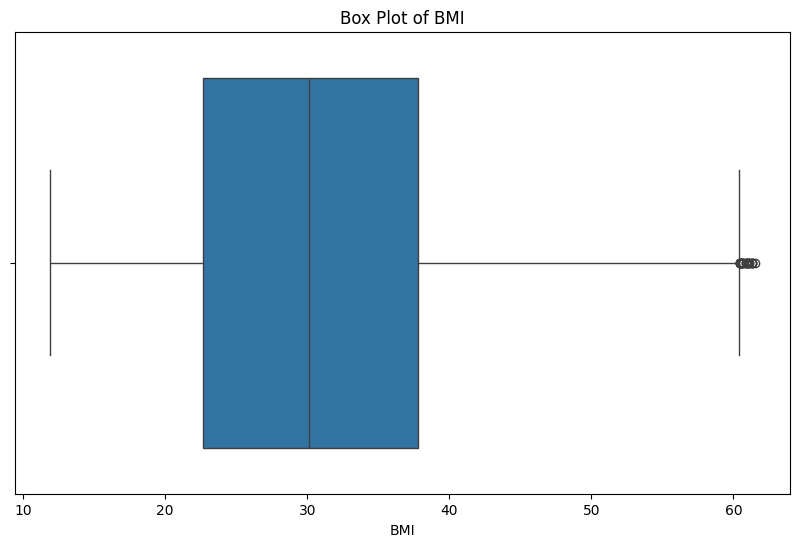

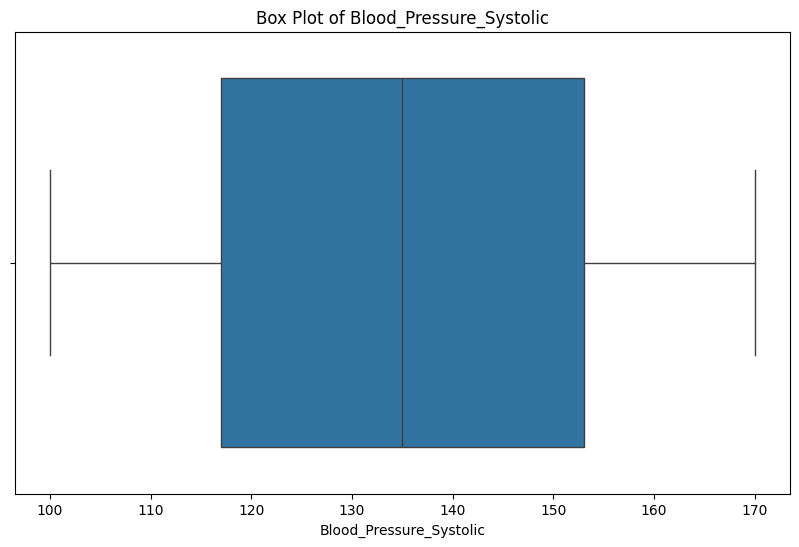

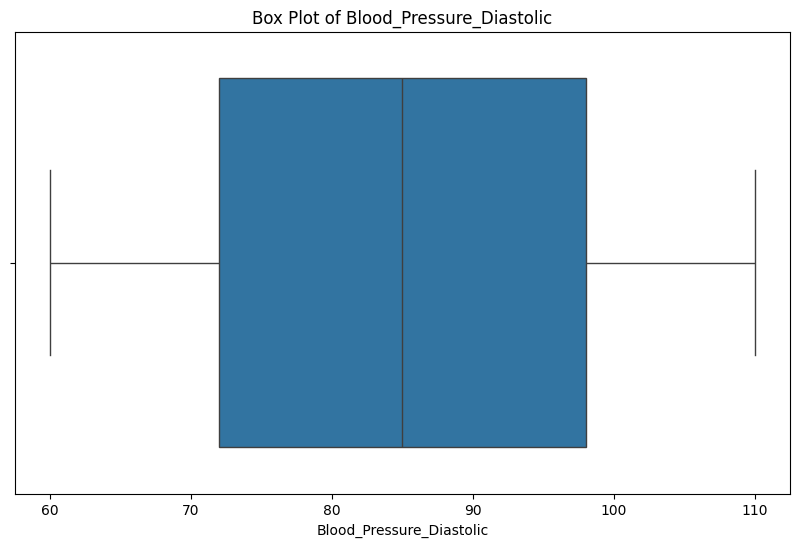

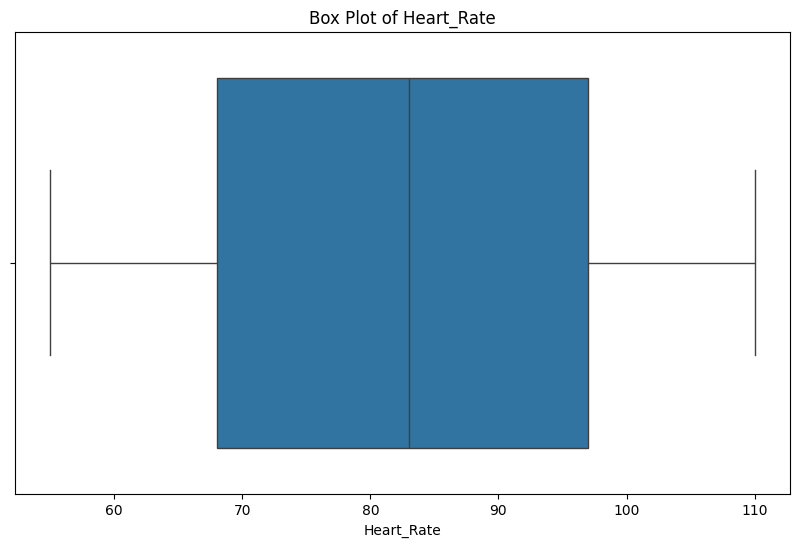

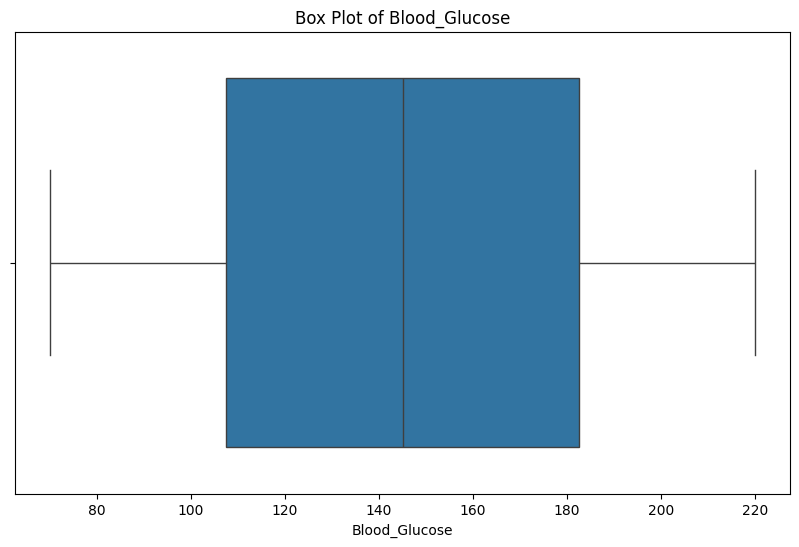

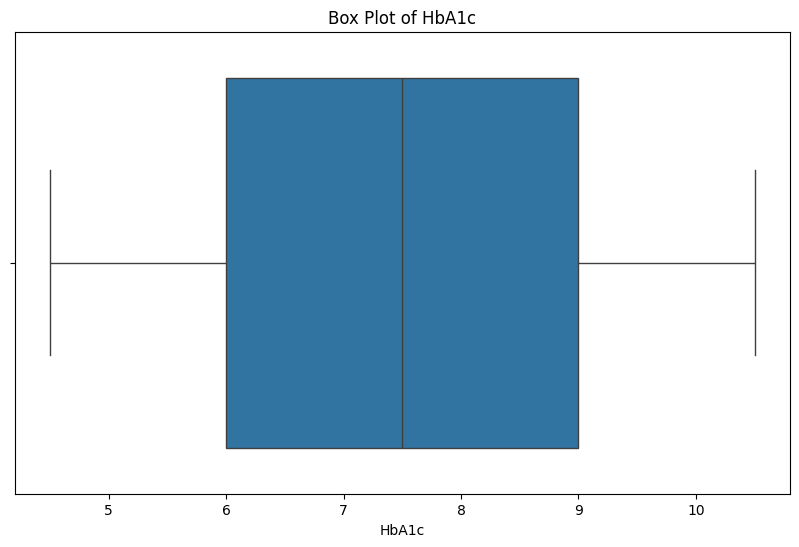

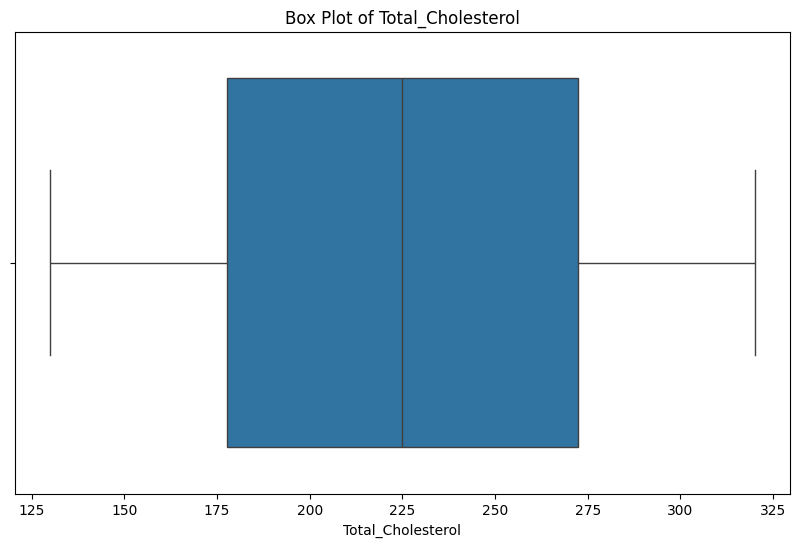

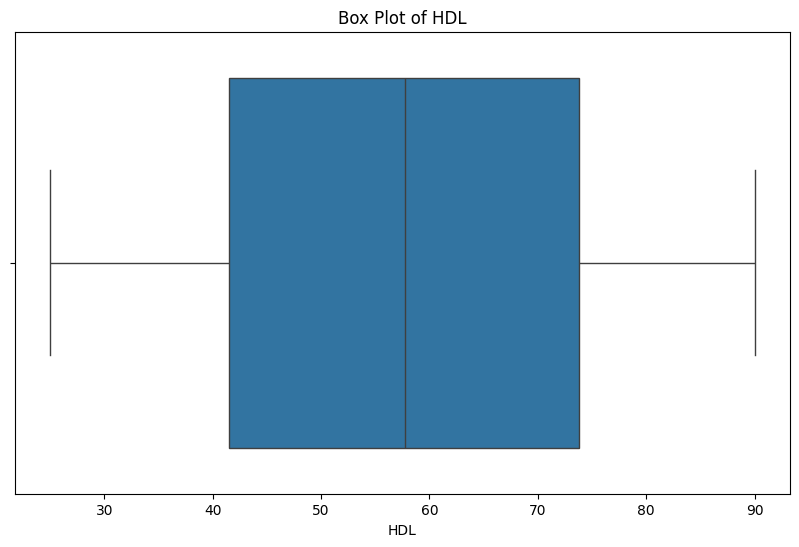

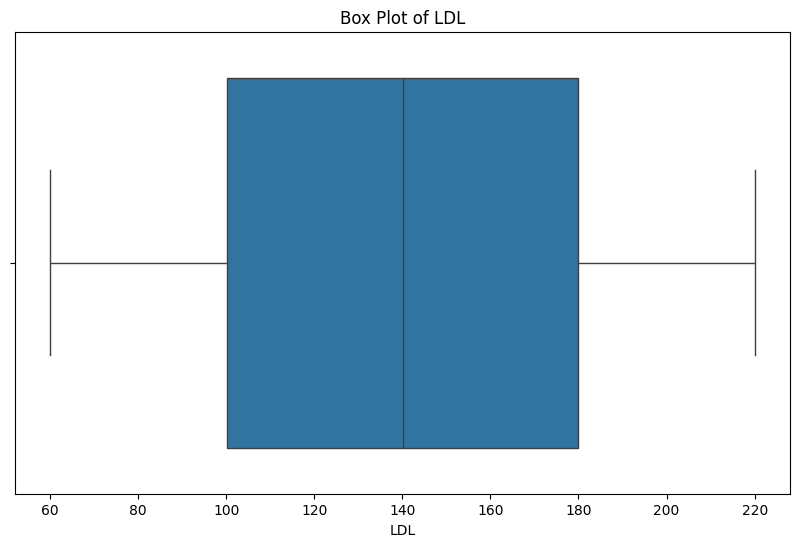

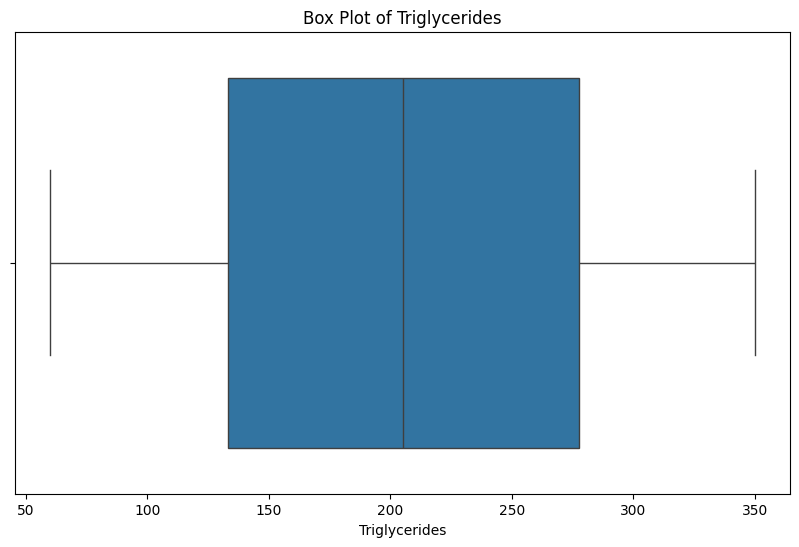

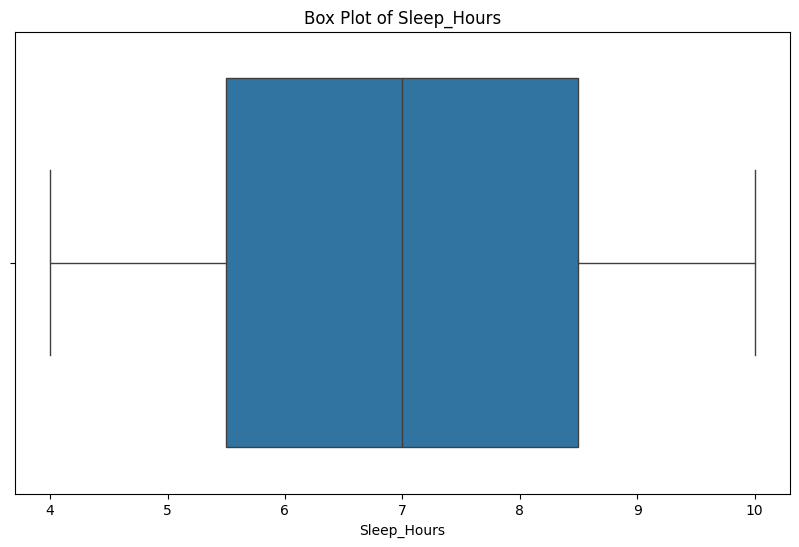

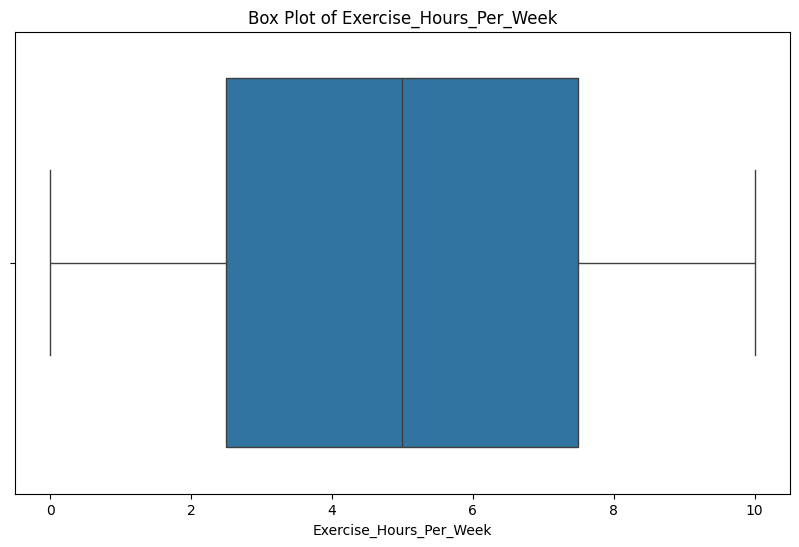

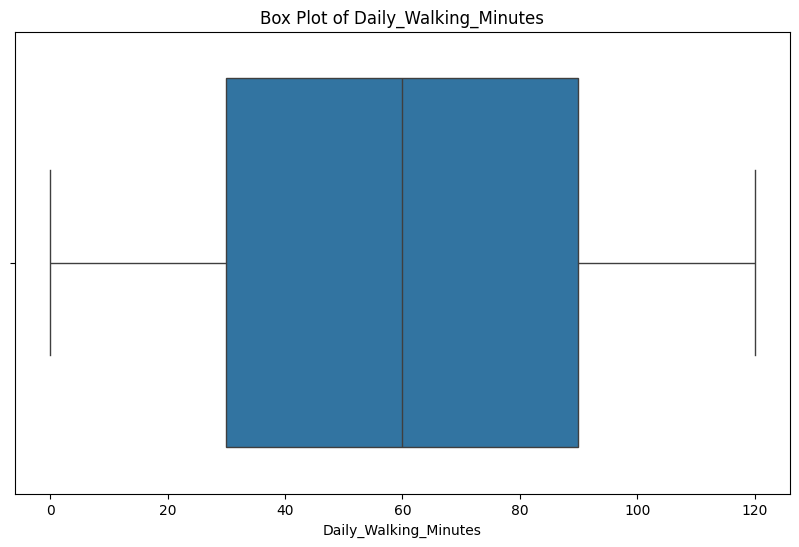

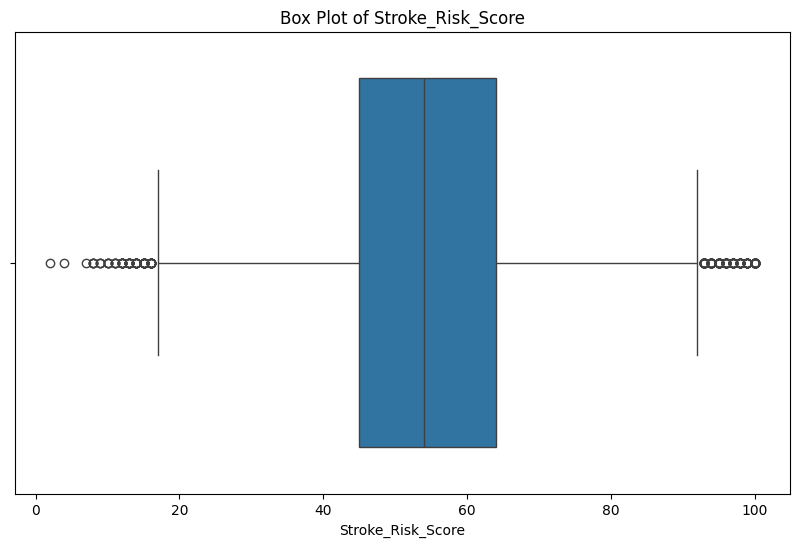

In [12]:
eda_numeric_features = df.select_dtypes(include=['number']).columns
for feature in eda_numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [13]:
print("Distribusi fitur yang mengandung outlier\n")
print(df["BMI"].value_counts())

Distribusi fitur yang mengandung outlier

BMI
32.6    207
24.0    202
24.3    199
22.2    197
21.2    196
       ... 
60.6      2
60.4      1
60.3      1
61.5      1
60.2      1
Name: count, Length: 494, dtype: int64


In [14]:
print("Distribusi Target")
print(df["Stroke_Risk"].value_counts())

Distribusi Target
Stroke_Risk
Moderate    34375
High        12112
Low          3513
Name: count, dtype: int64


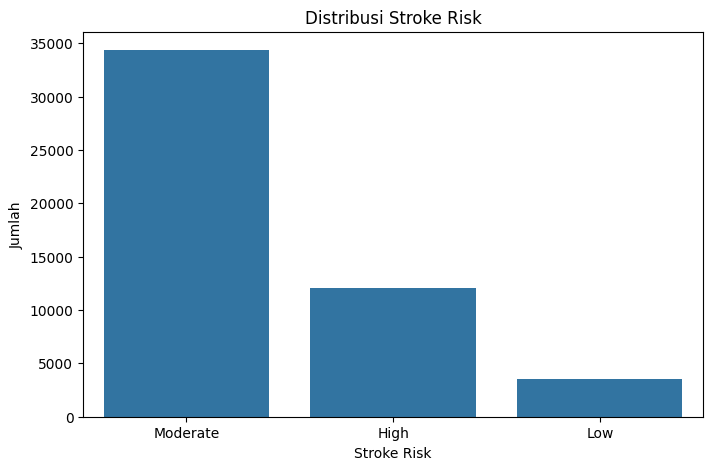

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Stroke_Risk")
plt.title("Distribusi Stroke Risk")
plt.xlabel("Stroke Risk")
plt.ylabel("Jumlah")
plt.show()

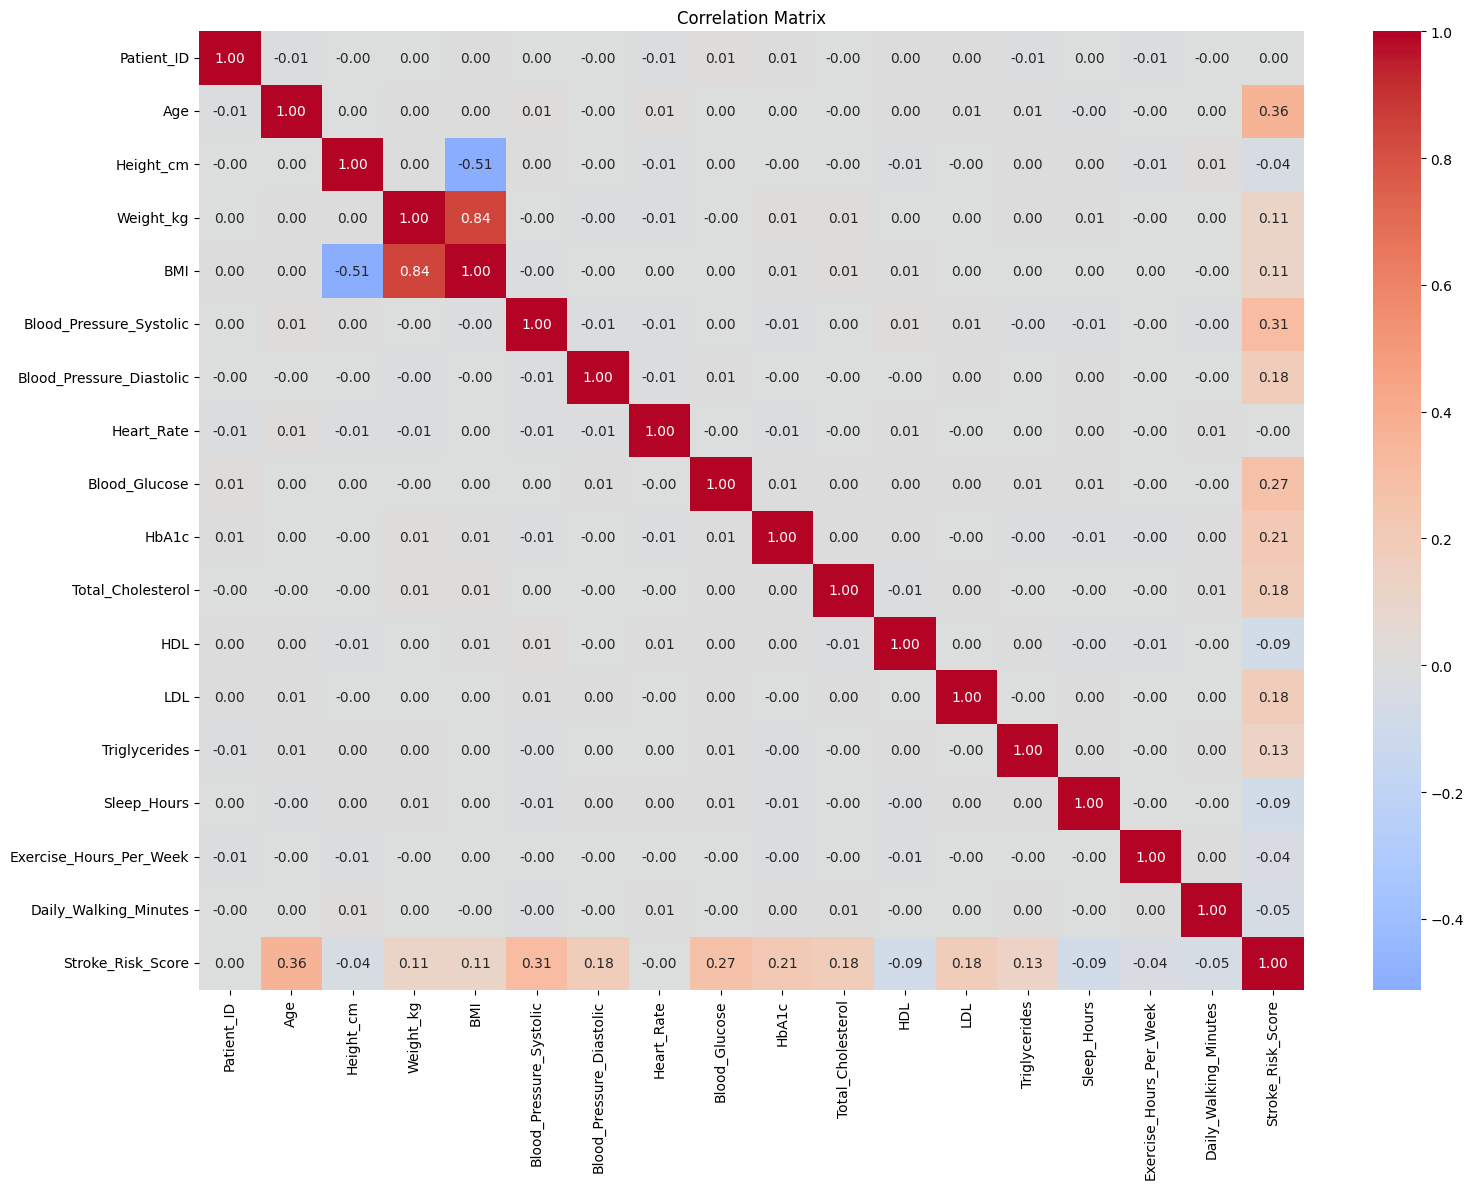

In [16]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', annot=True, fmt=".2f", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [17]:
column_drop = [
    "Patient_ID",
    "Stroke_Risk_Score",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed"
]
df.shape

(50000, 40)

In [18]:
df_model = df.drop(columns=column_drop)

df_model.shape

(50000, 36)

In [19]:
X = df_model.drop(columns="Stroke_Risk")
y = df_model["Stroke_Risk"]

print("X:", X.shape)
print("y:", y.shape)

X: (50000, 35)
y: (50000,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40000, 35)
X_test: (10000, 35)
y_train: (40000,)
y_test: (10000,)


In [21]:
numeric_features = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Heart_Rate",
    "Blood_Glucose",
    "HbA1c",
    "Total_Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Sleep_Hours",
    "Exercise_Hours_Per_Week",
    "Daily_Walking_Minutes"
]

In [22]:
ordinal_features = [
    "Alcohol_Consumption",
    "Physical_Activity_Level",
    "Stress_Level",
    "Diet_Quality",
    "Medication_Adherence",
    "Air_Pollution_Exposure"
]

ordinal_categories = [
    ["Never", "Occasionally", "Frequently"],
    ["Low", "Moderate", "High"],
    ["Low", "Moderate", "High"],
    ["Poor", "Average", "Healthy"],
    ["Poor", "Average", "Excellent"],
    ["Low", "Medium", "High"]
]

In [23]:
nominal_features = [
    "Gender",
    "Country",
    "Smoking_Status",
    "Family_History_Stroke",
    "Family_History_Heart_Disease",
    "Diabetes",
    "Hypertension",
    "Heart_Disease",
    "Previous_TIA",
    "Atrial_Fibrillation",
    "Chronic_Kidney_Disease",
    "Work_Type",
    "Residence_Type"
]

In [24]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=ordinal_categories, handle_unknown="use_encoded_value", unknown_value=-1))
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))
])

In [25]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("nominal", nominal_pipeline, nominal_features)
])

In [26]:
# MODEL 1 - LOGISTIC REGRESSION
logistic_model = Pipeline([  
    ("preprocessor", preprocessor), 
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Training
logistic_model.fit(X_train, y_train)

# Prediksi
y_pred_logistic = logistic_model.predict(X_test)

In [27]:
# MODEL 2 - RANDOM FOREST
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

# Training
random_forest_model.fit(X_train, y_train)

# Prediksi
y_pred_rf = random_forest_model.predict(X_test)

In [28]:
# MODEL 3 - HISTOGRAM GRADIENT BOOSTING
hist_gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingClassifier(max_iter=100, random_state=42))
])

# Training
hist_gradient_model.fit(X_train, y_train)

# Prediksi
y_pred_hgb = hist_gradient_model.predict(X_test)

In [29]:
# FUNGSI EVALUASI MODEL
def evaluasi_model(nama_model, y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    print("\n" + "=" * 60)
    print(nama_model)
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(classification_report(y_test, y_pred, zero_division=0))

    return [accuracy, precision, recall, f1]

In [30]:
# EVALUASI LOGISTIC REGRESSION
hasil_logistic = evaluasi_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

# EVALUASI RANDOM FOREST
hasil_rf = evaluasi_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

# EVALUASI HISTOGRAM GRADIENT BOOSTING
hasil_hgb = evaluasi_model(
    "Hist Gradient Boosting",
    y_test,
    y_pred_hgb
)


Logistic Regression
Accuracy  : 0.8466
Precision : 0.8121
Recall    : 0.7229
F1-Score  : 0.7587

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.72      0.76      2422
         Low       0.76      0.52      0.62       703
    Moderate       0.86      0.92      0.89      6875

    accuracy                           0.85     10000
   macro avg       0.81      0.72      0.76     10000
weighted avg       0.84      0.85      0.84     10000


Random Forest
Accuracy  : 0.8071
Precision : 0.9046
Recall    : 0.5324
F1-Score  : 0.5767

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.49      0.65      2422
         Low       0.99      0.12      0.21       703
    Moderate       0.79      0.99      0.88      6875

    accuracy                           0.81     10000
   macro avg       0.90      0.53      0.58     10000
weighted avg       0.84      0.81      0.77     10000


H

In [31]:
# PERBANDINGAN SEMUA MODEL
hasil_perbandingan = pd.DataFrame(  
    [
        hasil_logistic,
        hasil_rf,
        hasil_hgb
    ],
    
    columns=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    
    index=[
        "Logistic Regression",
        "Random Forest",
        "Hist Gradient Boosting"
    ]
)


print("\n" + "=" * 60)
print("PERBANDINGAN PERFORMA MODEL")
print("=" * 60)

display(
    hasil_perbandingan.round(4)
)


PERBANDINGAN PERFORMA MODEL


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8466,0.8121,0.7229,0.7587
Random Forest,0.8071,0.9046,0.5324,0.5767
Hist Gradient Boosting,0.9126,0.9372,0.7949,0.8488


In [32]:
# MENGURUTKAN MODEL BERDASARKAN F1-SCORE
print("\n" + "=" * 60)
print("PERINGKAT MODEL BERDASARKAN F1-SCORE")
print("=" * 60)

display(
    hasil_perbandingan
    .sort_values(
        by="F1-Score",
        ascending=False
    )
    .round(4)
)


PERINGKAT MODEL BERDASARKAN F1-SCORE


,Accuracy,Precision,Recall,F1-Score
Hist Gradient Boosting,0.9126,0.9372,0.7949,0.8488
Logistic Regression,0.8466,0.8121,0.7229,0.7587
Random Forest,0.8071,0.9046,0.5324,0.5767


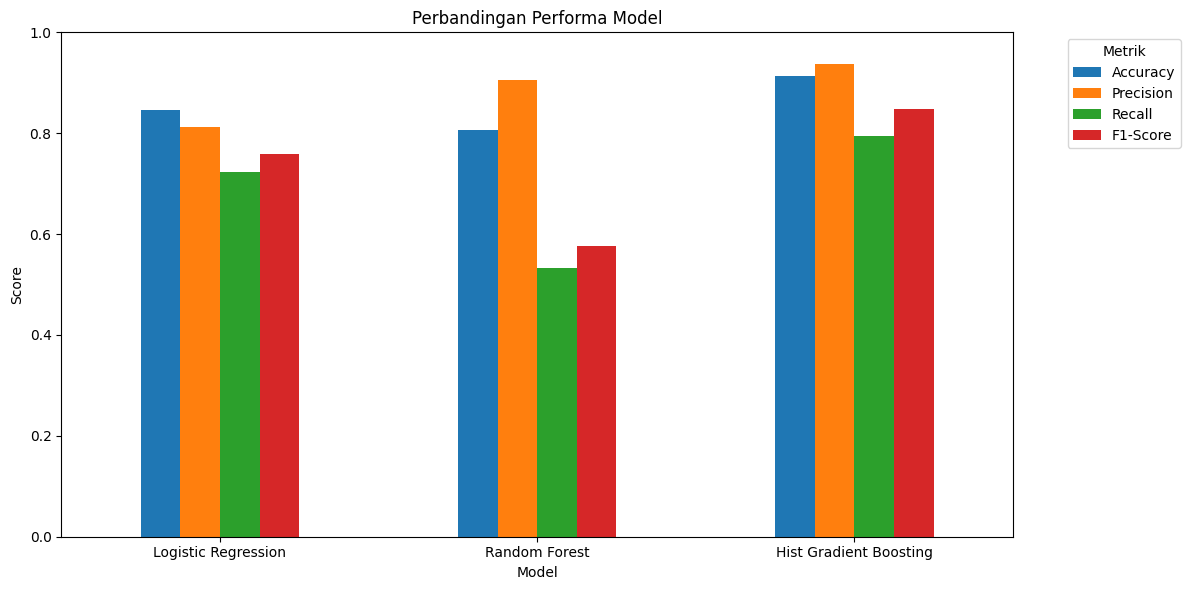

In [33]:
# VISUALISASI PERBANDINGAN MODEL
hasil_perbandingan.plot(kind="bar", figsize=(12, 6))
plt.title("Perbandingan Performa Model")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrik", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

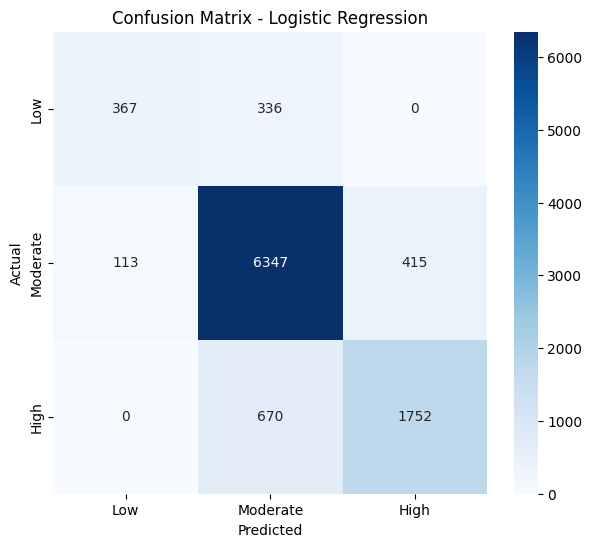

In [34]:
# CONFUSION MATRIX - LOGISTIC REGRESSION
labels = ["Low", "Moderate", "High"]

cm_logistic = confusion_matrix(y_test, y_pred_logistic, labels=labels)

plt.figure(figsize=(7, 6))

sns.heatmap(cm_logistic, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

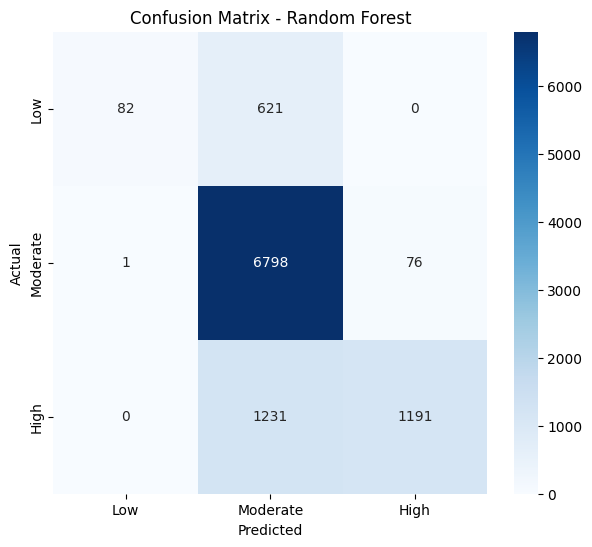

In [35]:
# CONFUSION MATRIX - RANDOM FOREST
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(7, 6))

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

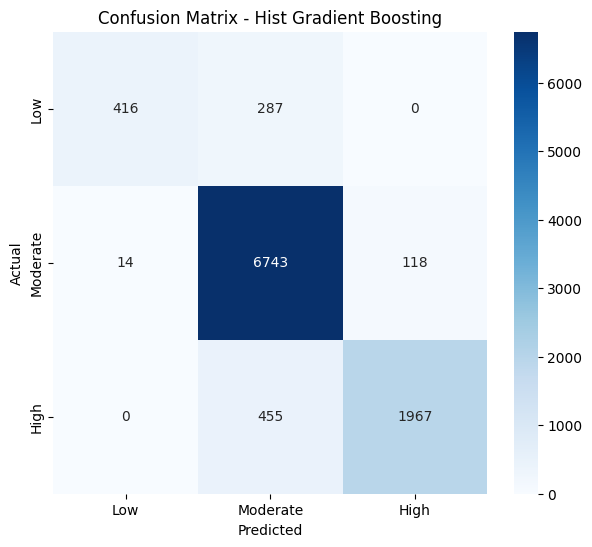

In [36]:
# CONFUSION MATRIX - HIST GRADIENT BOOSTING
cm_hgb = confusion_matrix(y_test, y_pred_hgb, labels=labels)

plt.figure(figsize=(7, 6))

sns.heatmap(cm_hgb, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)

plt.title( "Confusion Matrix - Hist Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [37]:
# MENENTUKAN MODEL TERBAIK
model_terbaik = hasil_perbandingan[
    "F1-Score"
].idxmax()

nilai_f1_terbaik = hasil_perbandingan.loc[
    model_terbaik,
    "F1-Score"
]

print("=" * 60)
print("MODEL TERBAIK")
print("=" * 60)

print("Model :", model_terbaik)
print(
    f"F1-Score : {nilai_f1_terbaik:.4f}"
)

MODEL TERBAIK
Model : Hist Gradient Boosting
F1-Score : 0.8488


In [38]:
# Penyimpanan Model
import joblib

joblib.dump(hist_gradient_model, "stroke_model.pkl")

['stroke_model.pkl']